# Klasterisasi Produk dengan K-Means

Produk dikelompokkan berdasarkan jumlah terjual, harga rata-rata, dan porsi jam ramai.

## 1. Muat Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

CSV = '../data/Transactions.csv'
df = pd.read_csv(CSV)
df.head()

C:\Users\Radit\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
C:\Users\Radit\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


,Outlet,Date,Time,NetSales,Tax,TotalAmount,ReceiptNumber,Items,TotalItem,PaymentMethod,UseLoyaltyCard
0,SHOP001,2025-01-02,07:01:05,20720.721,2279.279,23000,SHOP001JAN2500001,Basic Latte (Ice Arabica),1,BCA,0
1,SHOP001,2025-01-02,07:04:11,18018.018,1981.982,20000,SHOP001JAN2500002,BLACK (Houseblend),1,BCA,0
2,SHOP002,2025-01-02,07:10:46,39639.640,4360.360,44000,SHOP002JAN2500001,"Friendly Coffee (Hot), Shakencano",2,Cash,0
3,SHOP002,2025-01-02,07:14:25,36036.036,3963.964,40000,SHOP002JAN2500002,"BLACK (Arabica), Americano (Hot Arabica)",2,Cash,0
4,SHOP002,2025-01-02,07:23:05,36036.036,3963.964,40000,SHOP002JAN2500003,"WHITE (Arabica), Susu Oat",2,Cash,0


## 2. Agregasi per Produk

In [2]:
from sklearn.preprocessing import StandardScaler

df['Date'] = pd.to_datetime(df['Date'])
df['hour'] = pd.to_datetime(df['Time'], format='%H:%M:%S').dt.hour
df['Items'] = df['Items'].str.replace('Houesblend', 'Houseblend', regex=False)

ex = df.assign(Item=df['Items'].str.split(r',\s*')).explode('Item')
ex['Item'] = ex['Item'].str.strip()
ex['price'] = ex['TotalAmount'] / ex['TotalItem']

produk = ex.groupby('Item').agg(
    qty=('Item', 'size'),
    avg_price=('price', 'mean'),
    share_morning=('hour', lambda h: (h < 12).mean())).reset_index()
print(produk.shape)
produk.head()

(94, 4)


,Item,qty,avg_price,share_morning
0,Air Mineral,683,7331.625183,0.253294
1,Americano (Hot Arabica),706,20322.237960,0.250708
2,Americano (Hot Houseblend),641,20382.215289,0.254290
3,Americano (Ice Arabica),633,20119.273302,0.268562
4,Americano (Ice Houseblend),686,20287.172012,0.275510


## 3. Standarisasi

In [3]:
X = StandardScaler().fit_transform(produk[['qty', 'avg_price', 'share_morning']])
print(X.shape)

(94, 3)


## 4. Metode Elbow

C:\Users\Radit\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\Radit\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\Radit\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\Radit\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\Radit\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreatePro

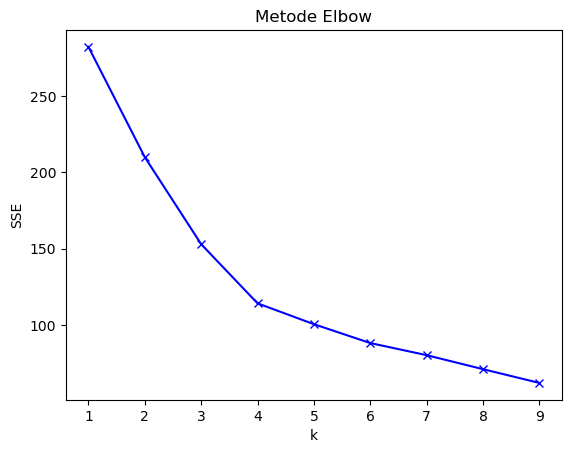

In [4]:
from sklearn.cluster import KMeans

sse = []
for k in range(1, 10):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    sse.append(km.inertia_)

plt.plot(range(1, 10), sse, 'bx-')
plt.xlabel('k')
plt.ylabel('SSE')
plt.title('Metode Elbow')
plt.show()

## 5. Klaster k=3

In [5]:
km = KMeans(n_clusters=3, n_init=10, random_state=42)
produk['klaster'] = km.fit_predict(X)
produk.groupby('klaster')[['qty', 'avg_price', 'share_morning']].mean().round(2)

,qty,avg_price,share_morning
klaster,,,
0,641.67,22950.98,0.27
1,686.42,23362.94,0.26
2,652.88,11887.89,0.27


## 6. Visualisasi

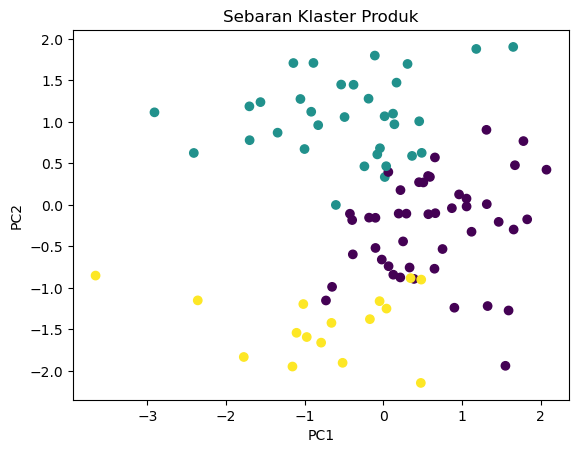

In [6]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
Z = pca.fit_transform(X)
plt.scatter(Z[:, 0], Z[:, 1], c=produk['klaster'], cmap='viridis')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('Sebaran Klaster Produk')
plt.show()